# Evaluation Benchmark
- ApSense Data-Driven Algorithm in PPG-Based Sleep Apnea Sensing
- by Wansiri Worawitayanon Student ID: 2330806

## Overview of ApSense Paper
- Obstructive Sleep Apnea window detection based on Deep Learning Model

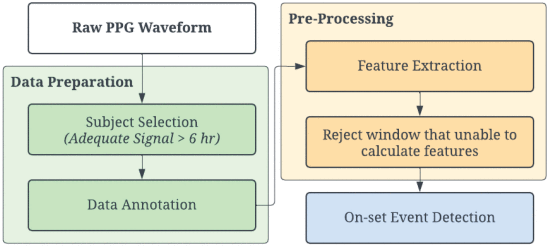

- Dataset: MESA and HeartBEAT Datasets
- Model : ApSense Model

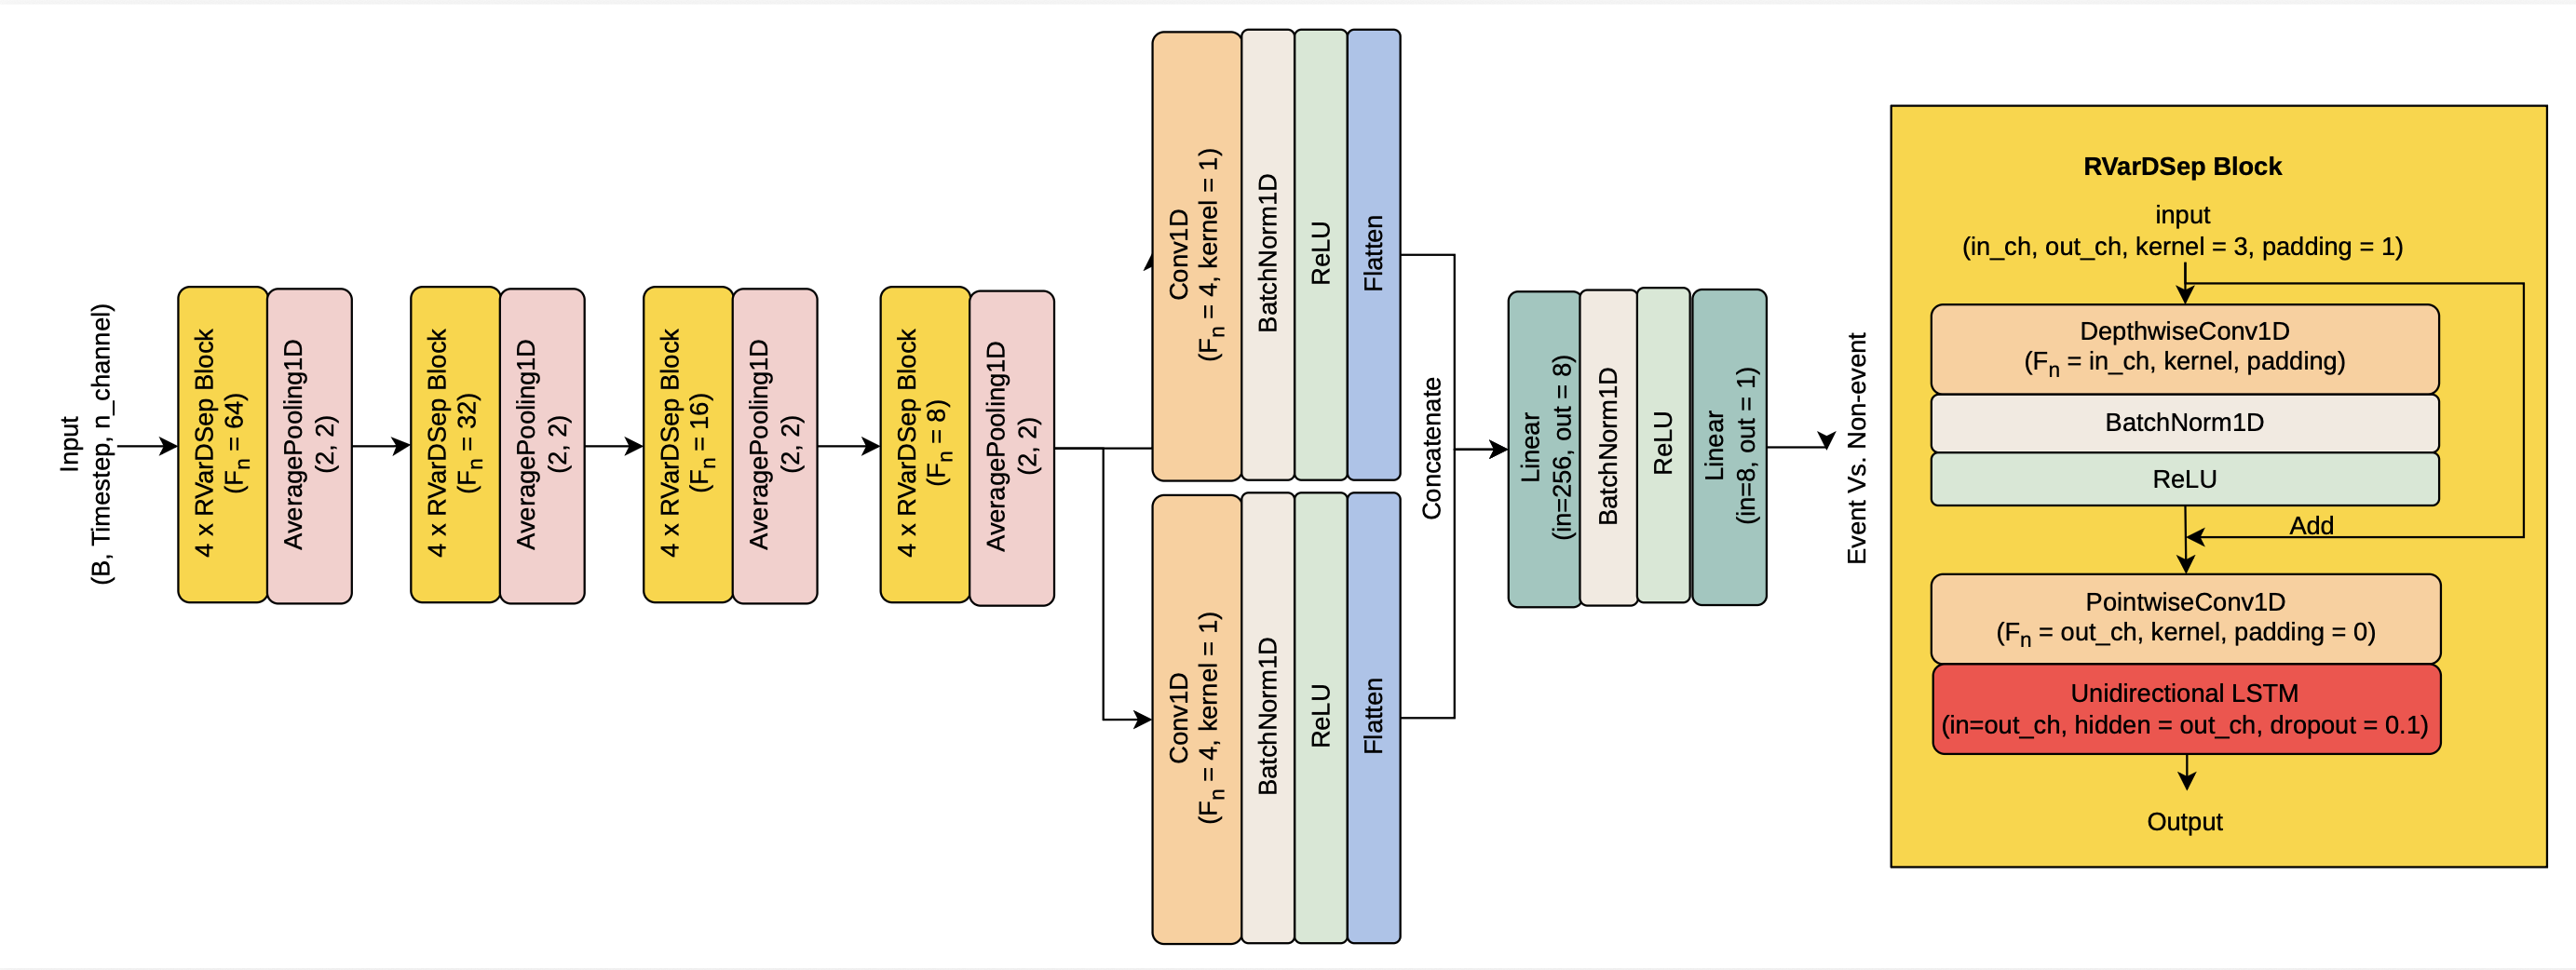

### Experiment Setup
#### Handling Imbalanced Data: The thing that I want to benchmark

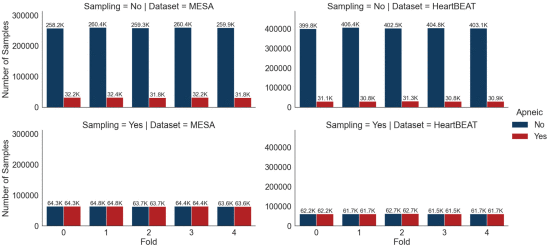

- Hybrid method: Oversample the minority class first, followed by downsampling the majority class to achieve the target class distribution.
- Original Imbalanced Data: Train the model using the original training data without applying any resampling techniques, preserving the actual class distribution
- Batch Sampler: Construct each mini-batch with 85 samples from the minority (positive) class and 171 samples from the majority class. Rotate the majority-class indices across mini-batches to ensure that different majority-class samples are utilized throughout training.
- SMOTE: Generate synthetic minority-class samples by interpolating between existing minority-class samples and their nearest neighbors.
- Adasyns: Generate synthetic minority-class samples adaptively, assigning more synthetic samples to minority-class instances that are harder to learn based on their local class distribution.

#### Validation step

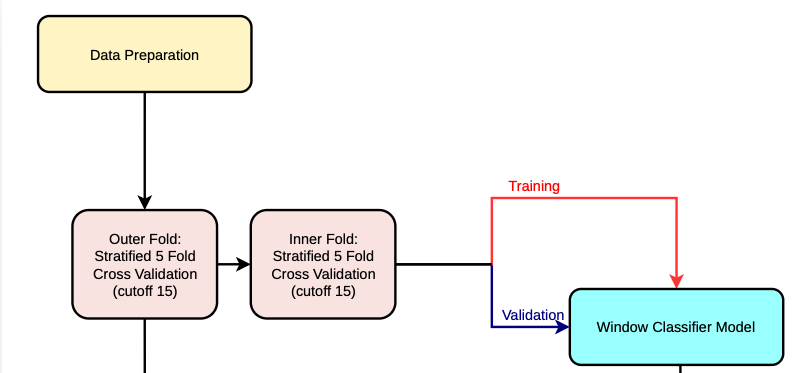
- Nested loop five fold cross validation step

# Method

## Requirement Library

pip install -r requirements.txt

## Data Preparation

### Load dataset
- MESA Dataset
1. Request access to the MESA dataset from https://sleepdata.org/datasets/mesa
2. Download the polysomnography (PSG) EDF files

- HeartBEAT Dataset
1.Request access to the HeartBEAT dataset from https://sleepdata.org/datasets/heartbeat
2.Download the PSG EDF files

### Event collection, Merge event and signal, Window segmentation, and Feature Extraction
- MESA Dataset: cd ./benchmark/code/MESA/
1. Event collection

python event.py \
    --metadata /home/Data/MESA/datasets/mesa-sleep-dataset-0.5.0.csv # File that we get from dataset \
    --annotate /home/Data/MESA/polysomnography/annotations-events-nsrr # File that we get from dataset \
    --output   /home/work/Apnea/ApSense/benchmark/preprocess/MESA/events/ # New folder that we want to locate the event

2. Merge event

python merge.py \
    --meta /home/Data/MESA/datasets/mesa-sleep-dataset-0.5.0.csv  # File that we get from dataset\
    --raw /home/Data/MESA/polysomnography/edfs # File that we get from dataset\
    --anno /home/work/Apnea/ApSense/benchmark/preprocess/MESA/events # Folder from the step 1\
    --hyp /home/Data/MESA/polysomnography/annotations-events-nsrr # Hypnogram File that we get from dataset \
    --output   /home/work/Apnea/ApSense/benchmark/preprocess/MESA/ppgcoordinate # New Folder that we want to locate the ppg with event coordination /

3. Window segmentation

python segment.py \
    --meta /home/Data/MESA/datasets/mesa-sleep-dataset-0.5.0.csv  # File that we get from dataset \
    --raw /home/work/Apnea/ApSense/benchmark/preprocess/MESA/ppgcoordinate # Folder from the step 2 \
    --output   /home/work/Apnea/ApSense/benchmark/preprocess/MESA/segments/ # New Folder that we want to locate ppg-window segmentation (60s overlap 30s with event on the first half of window)

4. Feature extraction

python preprocess.py \
    --meta /home/Data/MESA/datasets/mesa-sleep-dataset-0.5.0.csv # File that we get from dataset \
    --data_dir /home/work/Apnea/ApSense/benchmark/preprocess/MESA/segments # Folder from the step 3\
    --output_dir /home/work/Apnea/ApSense/benchmark/preprocess/MESA/feature # New Folder that we want to locate feature-window segmentation (60s overlap 30s with event on the first half of window)

- HeartBEAT Dataset: cd ./benchmark/code/HB/
1. Event collection

python event.py \
    --metadata /home/Data/heartbeat/datasets/heartbeat-baseline-dataset-0.4.0.csv # File that we get from dataset\
    --annotate /home/Data/heartbeat/polysomnography/annotations-events-nsrr/baseline # File that we get from dataset\
    --edf /home/Data/heartbeat/polysomnography/edfs/baseline # File that we get from dataset\
    --output   /home/work/Apnea/ApSense/benchmark/preprocess/HB/events/ # New folder that we want to locate the event

2. Merge event

python merge.py \
    --meta /home/Data/heartbeat/datasets/heartbeat-baseline-dataset-0.4.0.csv # File that we get from dataset\
    --raw /home/Data/heartbeat/polysomnography/edfs/baseline # File that we get from dataset\
    --anno /home/work/Apnea/ApSense/benchmark/preprocess/HB/events # Folder from the step 1\
    --hyp /home/Data/heartbeat/polysomnography/annotations-events-nsrr/baseline # File that we get from dataset\
    --output /home/work/Apnea/ApSense/benchmark/preprocess/HB/ppgcoordinate/ # New Folder that we want to locate ppg-window segmentation (60s overlap 30s with event on the first half of window)

3. Window Segmentation

python segment.py \
    --meta /home/Data/heartbeat/datasets/heartbeat-baseline-dataset-0.4.0.csv # File that we get from dataset\
    --raw /home/work/Apnea/ApSense/benchmark/preprocess/HB/ppgcoordinate # Folder from the step 2\
    --output   /home/work/Apnea/ApSense/benchmark/preprocess/HB/segments/ # New Folder that we want to locate ppg-window segmentation (60s overlap 30s with event on the first half of window)

4. Feature Extraction

python preprocess.py \
    --meta /home/Data/heartbeat/datasets/heartbeat-baseline-dataset-0.4.0.csv # File that we get from dataset\
    --data_dir /home/work/Apnea/ApSense/benchmark/preprocess/HB/segments # Folder from the step 3\
    --output_dir /home/work/Apnea/ApSense/benchmark/preprocess/HB/feature # New Folder that we want to locate feature-window segmentation (60s overlap 30s with event on the first half of window)

## Balance class method

- Access to ./benchmark/model/

1. original: Follow Apsense Paper

python original.py \
    --output # Path output directory \
    --feature # Feature directory that get from preprocess dataset (step 4) \
    --meta # Path metadata from dataset \
    --dataset # name of dataset ('MESA' or 'HB')

2. imbalance

python imbalance.py \
    --output # Path output directory \
    --feature # Feature directory that get from preprocess dataset (step 4) \
    --meta # Path metadata from dataset \
    --dataset # name of dataset ('MESA' or 'HB')

3. batchsampler

python batchsampler.py \
    --output # Path output directory \
    --feature # Feature directory that get from preprocess dataset (step 4) \
    --meta # Path metadata from dataset \
    --dataset # name of dataset ('MESA' or 'HB')

4. SMOTE

python smote.py \
    --output # Path output directory \
    --feature # Feature directory that get from preprocess dataset (step 4) \
    --meta # Path metadata from dataset \
    --dataset # name of dataset ('MESA' or 'HB')

5. ADASYN

python adasyn.py \
    --output # Path output directory \
    --feature # Feature directory that get from preprocess dataset (step 4) \
    --meta # Path metadata from dataset \
    --dataset # name of dataset ('MESA' or 'HB')

# Result

In [2]:
from sklearn.metrics import (
    balanced_accuracy_score, accuracy_score, f1_score,
    confusion_matrix, cohen_kappa_score, matthews_corrcoef, roc_auc_score
)
import numpy as np

def metrics(gt, pd):
    gt = np.array(gt).astype(int).flatten()
    pd = np.array(pd).astype(int).flatten()

    acc = accuracy_score(gt, pd)
    bal_acc = balanced_accuracy_score(gt, pd)
    f1 = f1_score(gt, pd, average='macro')

    cm = confusion_matrix(gt, pd, labels=[0, 1])
    tn, fp, fn, tp = cm.ravel()

    # sensitivity / specificity
    sen  = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    spec = tn / (tn + fp) if (tn + fp) > 0 else 0.0

    # PPV / NPV
    ppv = tp / (tp + fp) if (tp + fp) > 0 else 0.0   # precision
    npv = tn / (tn + fn) if (tn + fn) > 0 else 0.0

    cohen = cohen_kappa_score(gt, pd)
    mat = matthews_corrcoef(gt, pd)

    return acc, bal_acc, f1, sen, spec, ppv, npv, cm, cohen, mat


In [ ]:
from sklearn.metrics import precision_recall_curve, auc
import pandas as pd
import torch
from pathlib import Path
base = Path.cwd().parents[1]   # code/report -> benchmark

def report(path_file):
    df = pd.DataFrame(columns=['outer_fold','acc', 'bal_acc', 'f1', 'f1_w', 'sen', 'spec', 'auc', 'ppv', 'npv', 'aucpr'])
    y_prob_l = []
    y_true_l = []
    y_pred_l = []
    y_ap = []
    for i in range(5):
        fold_acc = []
        fold_bal = []
        fold_f1 = []
        fold_spec = []
        fold_sens = []
        fold_auc = []
        for j in range(5):
            result_path = f'{path_file}/output_outer_{i}_fold_{j}.pth'
            data = torch.load(result_path, map_location='cpu')
            y_true = data['y_true']
            y_pred = data['y_pred']
            y_prob = []
            for k in range(len(data['test_pred_prob'])):
                if data['test_pred_prob'][k].shape == ():
                    prob = data['test_pred_prob'][k]
                    fold_ap = np.log(prob / (1 - prob))
                    y_ap.append(fold_ap)
                    y_prob.append(data['test_pred_prob'][k])
                    y_prob_l.append(data['test_pred_prob'][k])
                    y_true_l.append(data['y_true'][k])
                    y_pred_l.append(data['y_pred'][k])
                else:
                    for l in range(len(data['test_pred_prob'][k])):
                        prob = data['test_pred_prob'][k][l]
                        fold_ap = np.log(prob / (1 - prob))
                        y_ap.append(fold_ap)
                        y_prob.append(data['test_pred_prob'][k][l])
                        y_prob_l.append(data['test_pred_prob'][k][l])
                        y_true_l.append(data['y_true'][k][l])
                        y_pred_l.append(data['y_pred'][k][l])
            y_prob = np.array(y_prob)
            acc, bal_acc, f1, sen, spec, ppv, npv, cm, cohen, mat = metrics(y_true, y_pred)
            fold_auc.append(roc_auc_score(y_true, y_prob))
            fold_acc.append(acc)
            fold_bal.append(bal_acc)
            fold_f1.append(f1)
            fold_spec.append(spec)
            fold_sens.append(sen)

            
        df.loc[i,'outer_fold'] = i
        df.loc[i,'acc'] = np.mean(fold_acc)
        df.loc[i,'bal_acc'] = np.mean(fold_bal)
        df.loc[i,'f1'] = np.mean(fold_f1)
        df.loc[i,'sen'] = np.mean(fold_sens)
        df.loc[i,'spec'] = np.mean(fold_spec)
        df.loc[i,'auc'] = np.mean(fold_auc)

    mean_acc = df['acc'].mean().round(3)
    mean_bal = df['bal_acc'].mean().round(3)
    mean_f1 = df['f1'].mean().round(3)
    mean_sen = df['sen'].mean().round(3)
    mean_spec = df['spec'].mean().round(3)
    mean_auc = df['auc'].mean().round(3)

    sd_acc = df['acc'].std().round(3)
    sd_bal = df['bal_acc'].std().round(3)
    sd_f1 = df['f1'].std().round(3)
    sd_sen = df['sen'].std().round(3)
    sd_spec = df['spec'].std().round(3)
    sd_auc = df['auc'].std().round(3)

    acc = f'{mean_acc} ± {sd_acc}'
    bal = f'{mean_bal} ± {sd_bal}'
    f1 = f'{mean_f1} ± {sd_f1}'
    sen = f'{mean_sen} ± {sd_sen}'
    spec = f'{mean_spec} ± {sd_spec}'
    auca = f'{mean_auc} ± {sd_auc}'
    return acc, bal, f1, sen, spec, auca

## MESA dataset

In [4]:
base = '/home/work/Apnea/ApSense/benchmark'
methods = ['original', 'imbalance', 'batchsampler', 'smote', 'adasyn']

result = pd.DataFrame(columns=['method', 'accuracy', 'balanced accuracy',
                               'f1-score', 'sensitivity', 'specificity', 'AUC'])
for m in methods:
    result.loc[len(result)] = [m, *report(f'{base}/{m}/MESA/test')]

result


,method,accuracy,balanced accuracy,f1-score,sensitivity,specificity,AUC
0,original,0.649 ± 0.024,0.686 ± 0.009,0.574 ± 0.019,0.74 ± 0.042,0.632 ± 0.034,0.751 ± 0.012
1,imbalance,0.843 ± 0.009,0.505 ± 0.005,0.47 ± 0.012,0.014 ± 0.014,0.996 ± 0.003,0.743 ± 0.038
2,batchsampler,0.793 ± 0.014,0.629 ± 0.008,0.618 ± 0.011,0.392 ± 0.016,0.867 ± 0.016,0.755 ± 0.011
3,smote,0.734 ± 0.009,0.629 ± 0.011,0.595 ± 0.007,0.476 ± 0.03,0.782 ± 0.015,0.723 ± 0.01
4,adasyn,0.735 ± 0.01,0.627 ± 0.009,0.594 ± 0.008,0.47 ± 0.028,0.785 ± 0.016,0.724 ± 0.007


Due to the event detection which composed of very imbalance class data, the metrics that we will focus in balanced accuracy, f1-score, sensitivity, and AUC. The original method achieved the highest balanced accuracy and sensitivity, indicating its ability to detect a larger proportion of event windows despite the class imbalance. In contrast, the imbalance method achieved the highest accuracy but exhibited extremely low sensitivity and high specificity, suggesting a strong bias toward the majority non-event class. This is the reason why this work need to balanced the data before training and validation model. However, batch sampler methood achieved the highest F1-score and AUC. This indicate that batch sampler method worked in highlight the importance of considering class-specific performance metrics rather than relying solely on overall accuracy when evaluating event detection under highly imbalanced conditions.

# HeartBEAT Dataset

In [5]:
import pandas as pd
base = '/home/work/Apnea/ApSense/benchmark'
methods = ['original', 'imbalance', 'batchsampler', 'smote', 'adasyn']

result = pd.DataFrame(columns=['method', 'accuracy', 'balanced accuracy',
                               'f1-score', 'sensitivity', 'specificity', 'AUC'])
for m in methods:
    result.loc[len(result)] = [m, *report(f'{base}/{m}/HB/test')]

result


,method,accuracy,balanced accuracy,f1-score,sensitivity,specificity,AUC
0,original,0.697 ± 0.009,0.752 ± 0.012,0.623 ± 0.008,0.83 ± 0.031,0.673 ± 0.013,0.835 ± 0.013
1,imbalance,0.855 ± 0.006,0.607 ± 0.015,0.628 ± 0.021,0.25 ± 0.03,0.964 ± 0.004,0.845 ± 0.013
2,batchsampler,0.814 ± 0.008,0.711 ± 0.012,0.683 ± 0.009,0.564 ± 0.03,0.859 ± 0.011,0.842 ± 0.009
3,smote,0.775 ± 0.01,0.713 ± 0.008,0.658 ± 0.009,0.625 ± 0.018,0.801 ± 0.013,0.823 ± 0.009
4,adasyn,0.768 ± 0.01,0.716 ± 0.007,0.655 ± 0.009,0.64 ± 0.006,0.791 ± 0.011,0.822 ± 0.009


Similarly, The original method achieved the highest balanced accuracy and sensitivity, indicating its ability to detect a larger proportion of event windows despite the class imbalance. However, this performance came at the expense of the lower specificity, suggesting a higher rate of false-positive predictions. In contrast, the imbalance method achieved the highest accuracy with highest specificity and lowest sensitivity indicate that the model biased the majority non-event class despite its high overall accuracy. The batchsampler method achieved the highest F1-score.

# Conclusion

Each method applied to improve model performance resulted in different evaluation metrics, reflecting different objectives of this study. For prescreening applications, where minimizing false negatives is a priority, the original method may be more appropriate because it provides higher sensitivity and reduces the risk of missing events. On the other hand, the batch sampler may be preferable in situations where high specificity is required, such as urgent case identification, to reduce false-positive detections.